# Q3: Stitching pairs of images 
    
The first step is to write code to stitch together a single pair of images. For this part, you will be working with uttower_left.JPG and uttower_right.JPG pair

Steps:
- Compute SIFT key-points and descriptors for both images.
- Calculate distances between descriptors in the first image and those in the second to build a similarity matrix.
- From this matrix, select candidate matches. You may either keep all pairs below a distance threshold or choose the top few hundred pairs with the smallest distances.
- Run RANSAC to estimate a homography mapping one image onto the other. Report the number of inliers and the average residual for the inliers (squared distance between the point coordinates in one image and the transformed coordinates of the matching point in the other image). Also, display the locations of inlier matches in both images. For RANSAC, a very simple implementation is sufficient. Use four matches to initialize the homography in each iteration. You should
output a single transformation that gets the most inliers in the course of all the iterations. For the various RANSAC parameters (number of iterations, inlier threshold), play around with a few "reasonable" values and pick the ones that work best.
- Warp one image onto the other using the estimated transformation.
- Create a canvas large enough to hold both warped images. Blend them into a panorama by averaging pixel values in the overlapping region

In [61]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
from scipy.signal.windows import gaussian

### Old Functions from other questions

In [62]:
def cross_correlation_2d(img, kernel, pad=True):
    """
    We do cross correlation with this func. using padding to decide if u want to have zero padding
    """
    img_h, img_w = img.shape
    kernel_h, kernel_w = kernel.shape

    if pad:
        pad_top_bot = kernel_h//2
        pad_left_right = kernel_w//2
        output_h, output_w = img_h, img_w
        img = np.pad(array=img,pad_width=(pad_top_bot, pad_left_right), constant_values=0)
    else:
        output_h, output_w = img_h - kernel_h+1, img_w-kernel_w+1
        
    output_img = np.zeros((output_h, output_w))

    for y in range(output_h):  #move down
        for x in range(output_w): #right
            img_piece = img[y:y+kernel_h, x:x+kernel_w]
            mult = np.multiply(img_piece, kernel)
            output_img[y][x] = np.sum(mult)
    
    return output_img

In [63]:
def convolve_2d(img, kernel, pad=True):
    impulse = np.zeros_like(kernel)
    kernel_h, kernel_w = kernel.shape
    impulse[kernel_h//2, kernel_w//2] = 1
    flipped_kernel = cross_correlation_2d(impulse, kernel, pad=True) #impulse is what my img is, need to have it samesize

    output_img = cross_correlation_2d(img, flipped_kernel, pad=pad)

    return output_img

In [64]:
def gaussian_kernel(n, std):
    """Returns a nxn gaussian kernel"""
    std_temp = std/np.sqrt(2) #to fix the issue due to gaussian kernel ending up with std of sigma root2 

    gauss_1d = gaussian(n, std_temp)
    kernel = np.outer(gauss_1d, gauss_1d) #separable
    kernel = kernel / np.sum(kernel) #normalisation
    return kernel

# Writing the SIFT Algorithm

In [65]:
img_left = cv2.imread('uttower_left.JPG', cv2.IMREAD_GRAYSCALE)
img_right = cv2.imread('uttower_right.JPG', cv2.IMREAD_GRAYSCALE)

### Step1: Scale Space extrema detection
 
 - constructing scale space(gaussian pyramid octaves)- one octave means sigma will double
 - find the Difference of guassians, since its faster than Laplacian of gausaian
 - select pixel if it is bigger or smaller than all 26 around- also perform edge supression

#### Constructing the gaussian pyramid

In [66]:
def make_gaussian_pyramid(img, tot_octaves=3, tot_scales=5, sigma=1.6):
    pyramid = []
    k = 2**(1.0/tot_scales)
    
    # Pre-smooth the input image for the first octave
    current_img = img.astype(np.float64)
    kernel_size = int(6*np.ceil(sigma)+1)
    if kernel_size % 2 == 0:
        kernel_size += 1
    pre_smooth_kernel = gaussian_kernel(kernel_size, sigma)
    current_img = convolve_2d(current_img, pre_smooth_kernel)

    for octave in range(tot_octaves):
        curr_octave_imgs = []

        for scale in range(1, tot_scales+3):
            curr_sigma = sigma * (k**scale)
            kernel_size = int(6*np.ceil(curr_sigma)+1)
            if kernel_size % 2 == 0:
                kernel_size += 1

            kernel = gaussian_kernel(kernel_size, curr_sigma)
            blurred_img = convolve_2d(current_img, kernel)

            curr_octave_imgs.append(blurred_img)
        
        pyramid.append(curr_octave_imgs)
        
        # Prep for next octave
        if octave < tot_octaves - 1:  # Don't resize after the last octave
            height, width = curr_octave_imgs[-3].shape
            current_img = cv2.resize(curr_octave_imgs[-3], (width//2, height//2), cv2.INTER_NEAREST)
    
    return pyramid

### making the DoG pyramid now

In [67]:
def make_dog_pyramid(gaussian_pyramid):
    dog_pyramid = []

    for octave in gaussian_pyramid:
        octave_dogs = []

        for i in range(len(octave) - 1):
            dog = octave[i+1] - octave[i]
            octave_dogs.append(dog)

        dog_pyramid.append(octave_dogs)
    
    return dog_pyramid

In [68]:
def edge_supression(image, x, y):

    # Calculate second derivatives
    Dxx = image[y, x+1] + image[y, x-1] - 2*image[y, x]
    Dyy = image[y+1, x] + image[y-1, x] - 2*image[y, x]
    Dxy = (image[y+1, x+1] + image[y-1, x-1] - 
           image[y+1, x-1] - image[y-1, x+1]) / 4.0
    
    # Calculate determinant and trace
    det_hessian = Dxx * Dyy - Dxy * Dxy
    trace_hessian = Dxx + Dyy
    
    # Edge suppression test
    # det_hessian > 0 ensures we have a well-defined extremum
    # The ratio test removes edge responses (Harris corner detector principle)
    return det_hessian > 0 and (trace_hessian * trace_hessian / det_hessian) < 12.

In [69]:
def find_extrema(dog_pyramid, contrast_threshold=0.01):
    keypoints = []

    for octave_idx, octave in enumerate(dog_pyramid):
        for scale_idx in range(1, len(octave)-1):  

            prev_img = octave[scale_idx-1]
            curr_img = octave[scale_idx]
            next_img = octave[scale_idx+1]

            height, width = curr_img.shape

            for y in range(1, height-1):
                for x in range(1, width-1):

                    neighbors_3d = np.array([
                        prev_img[y-1:y+2, x-1:x+2],
                        curr_img[y-1:y+2, x-1:x+2], 
                        next_img[y-1:y+2, x-1:x+2]
                    ])
                    
                    center_val = curr_img[y, x]
                    
                    # Check for max or min
                    is_max = center_val == np.max(neighbors_3d)
                    is_min = center_val == np.min(neighbors_3d)
                    
                    if (is_max or is_min) and abs(center_val) > contrast_threshold:
                        # hessian edge suprression
                        if edge_supression(curr_img, x, y):
                            
                            scale_factor = 2 ** octave_idx
                            actual_x = x * scale_factor
                            actual_y = y * scale_factor
                            
                            keypoints.append({
                                'x': actual_x,
                                'y': actual_y,
                                'octave': octave_idx,
                                'scale': scale_idx,
                                'response': abs(center_val)
                            })
    
    return keypoints

### assiging orientations to the keypoints

In [70]:
def compute_gradient_at_point(image, x, y):
    """find gradient magnitude and orientation at a single point"""
    dx = image[y, x+1] - image[y, x-1]
    dy = image[y+1, x] - image[y-1, x]
    
    magnitude = np.sqrt(dx*dx + dy*dy)
    orientation = np.arctan2(dy, dx) * 180 / np.pi
    
    if orientation < 0:
        orientation += 360
    
    return magnitude, orientation

In [71]:
def compute_window_gradients(octave_img, local_x, local_y, window_size=16):
    """find gradients for all pixels in a window around a keypoint"""
    half_size = window_size // 2
    
    y_start = max(1, local_y - half_size)
    y_end = min(octave_img.shape[0] - 1, local_y + half_size)
    x_start = max(1, local_x - half_size)
    x_end = min(octave_img.shape[1] - 1, local_x + half_size)
    
    magnitudes = []
    orientations = []
    
    for y in range(y_start, y_end):
        for x in range(x_start, x_end):
            magnitude, orientation = compute_gradient_at_point(octave_img, x, y)
            magnitudes.append(magnitude)
            orientations.append(orientation)
    
    return magnitudes, orientations

In [72]:
def find_dominant_orientation(orientations, magnitudes):
    """Find the dominant orientation from orientation histogram"""
    hist, bins = np.histogram(orientations, bins=36, range=(0, 360), weights=magnitudes)
    peak_idx = np.argmax(hist)
    dominant_orientation = bins[peak_idx] + (bins[1] - bins[0]) / 2
    return dominant_orientation

In [73]:
def is_keypoint_valid(local_x, local_y, img_shape):
    """to check if keypoint is far enough from image borders for gradient computation"""
    return (local_x >= 2 and local_y >= 2 and 
            local_x < img_shape[1] - 2 and local_y < img_shape[0] - 2)

In [74]:
def assign_orientations(keypoints, gaussian_pyramid):
    """assign orientations to keypoints"""
    oriented_keypoints = []
    
    for kp in keypoints:
        octave_img = gaussian_pyramid[kp['octave']][kp['scale']]
        
        
        scale_factor = 2 ** kp['octave']
        local_x = int(kp['x'] / scale_factor) # conversion to local coords in cur octave
        local_y = int(kp['y'] / scale_factor)
        
       
        if not is_keypoint_valid(local_x, local_y, octave_img.shape):
            continue
        
        # find gradiants in window around kp
        magnitudes, orientations = compute_window_gradients(octave_img, local_x, local_y)
        
        if len(orientations) > 0:
            dominant_orientation = find_dominant_orientation(orientations, magnitudes)
            
            kp['orientation'] = dominant_orientation
            kp['magnitude'] = np.mean(magnitudes)
            oriented_keypoints.append(kp)
    
    return oriented_keypoints

### extraction of descriptors

In [ ]:
def extract_descriptors(keypoints, gaussian_pyramid):
    descriptors = []
    valid_keypoints = []
    
    for kp in keypoints:
        octave_img = gaussian_pyramid[kp['octave']][kp['scale']]
        
        scale_factor = 2 ** kp['octave']
        local_x = int(kp['x'] / scale_factor)
        local_y = int(kp['y'] / scale_factor)
    
        if local_x < 10 or local_y < 10 or local_x >= octave_img.shape[1]-10 or local_y >= octave_img.shape[0]-10:
            continue
        
        #get 16x16 window around keypoint
        window = octave_img[local_y-8:local_y+8, local_x-8:local_x+8]
        
        if window.shape != (16, 16):
            continue
        
        #Compute gradients
        gy, gx = np.gradient(window.astype(np.float64))
        magnitude = np.sqrt(gx*gx + gy*gy)
        orientation = np.arctan2(gy, gx) * 180 / np.pi
        
        #Make angles relative to keypoint orientation
        orientation = orientation - kp['orientation']
        orientation[orientation < 0] += 360
        orientation[orientation >= 360] -= 360
        
        #Create descriptor (4x4 grid of 8-bin histograms)
        descriptor = []
        
        for i in range(4):
            for j in range(4):
                #4x4 pixel subregion
                sub_mag = magnitude[i*4:(i+1)*4, j*4:(j+1)*4]
                sub_ori = orientation[i*4:(i+1)*4, j*4:(j+1)*4]
                
                # 8-bin orientation histogram
                hist, _ = np.histogram(sub_ori.flatten(), bins=8, range=(0, 360), 
                                     weights=sub_mag.flatten())
                descriptor.extend(hist)
        
        #Normalize descriptor
        descriptor = np.array(descriptor, dtype=np.float64)
        norm = np.linalg.norm(descriptor)
        if norm > 0:
            descriptor = descriptor / norm
            # Clip values > 0.2 and renormalize
            descriptor = np.clip(descriptor, 0, 0.2)
            norm = np.linalg.norm(descriptor)
            if norm > 0:
                descriptor = descriptor / norm
        
        descriptors.append(descriptor)
        valid_keypoints.append(kp)
    
    return valid_keypoints, np.array(descriptors)

In [76]:
def detect_and_compute_sift(image, num_octaves=3, num_scales=5, sigma=1.6, contrast_threshold=0.01):
    if len(image.shape) == 3:
        gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    else:
        gray = image
    
    gray = gray.astype(np.float64) / 255.0
    
    gaussian_pyramid = make_gaussian_pyramid(gray, num_octaves, num_scales, sigma)
    dog_pyramid = make_dog_pyramid(gaussian_pyramid)
    
    
    keypoints = find_extrema(dog_pyramid, contrast_threshold)
    keypoints = assign_orientations(keypoints, gaussian_pyramid)
    
    if len(keypoints) == 0:
        return [], np.array([])
    
    
    valid_keypoints, descriptors = extract_descriptors(keypoints, gaussian_pyramid)
    
    return valid_keypoints, descriptors

## matching descriptors with each other

In [77]:
def match_descriptors(desc1, desc2, ratio_threshold=0.75):
    matches = []
    
    for i, d1 in enumerate(desc1):
        distances = []
        for j, d2 in enumerate(desc2):
            dist = np.linalg.norm(d1 - d2)
            distances.append((dist, j))
        
        distances.sort()
        
        if len(distances) >= 2:
            best_dist, best_idx = distances[0]
            second_dist, _ = distances[1]
            
            # lowes ratio
            if second_dist > 0 and best_dist / second_dist < ratio_threshold:
                matches.append((i, best_idx, best_dist))
    
    return matches

### find homography

In [78]:
def compute_homography(pts1, pts2):
    
    n = len(pts1)
    A = np.zeros((2*n, 9))
    
    for i in range(n):
        x1, y1 = pts1[i]
        x2, y2 = pts2[i]
        
        A[2*i] = [x1, y1, 1, 0, 0, 0, -x2*x1, -x2*y1, -x2]
        A[2*i+1] = [0, 0, 0, x1, y1, 1, -y2*x1, -y2*y1, -y2]
    
    #Solve using SVD
    try:
        _, _, V = np.linalg.svd(A)
        H = V[-1].reshape(3, 3)
        
        #Normalize by bottom-right element
        if abs(H[2, 2]) > 1e-10:
            H = H / H[2, 2]
        
        return H
    except:
        return None

In [79]:
def apply_homography(H, points):
    points = np.array(points)
    if points.shape[1] == 2:
        points_homo = np.column_stack([points, np.ones(len(points))])
    else:
        points_homo = points
    
    transformed = (H @ points_homo.T).T
    w = transformed[:, 2]
    w[w == 0] = 1e-10
    transformed_cart = transformed[:, :2] / w[:, np.newaxis]
    
    return transformed_cart

### ransac logic

In [80]:
def ransac_homography(matches, kp1, kp2, threshold=5.0, max_iterations=2000):
    if len(matches) < 4:
        return None, []
    
    best_H = None
    best_inliers = []
    best_num_inliers = 0
    
    for _ in range(max_iterations):
        sample_indices = np.random.choice(len(matches), 4, replace=False)
        sample_matches = [matches[i] for i in sample_indices]
        
        pts1 = [(kp1[m[0]]['x'], kp1[m[0]]['y']) for m in sample_matches]
        pts2 = [(kp2[m[1]]['x'], kp2[m[1]]['y']) for m in sample_matches]
        
        H = compute_homography(pts1, pts2)
        if H is None:
            continue
        
        inliers = []
        for i, (idx1, idx2, _) in enumerate(matches):
            pt1 = np.array([kp1[idx1]['x'], kp1[idx1]['y']])
            pt2 = np.array([kp2[idx2]['x'], kp2[idx2]['y']])
            
            try:
                pt1_transformed = apply_homography(H, [pt1])[0]
                error = np.linalg.norm(pt1_transformed - pt2)
                
                if error < threshold:
                    inliers.append(i)
            except:
                continue
        
        if len(inliers) > best_num_inliers:
            best_H = H
            best_inliers = inliers
            best_num_inliers = len(inliers)
    
    return best_H, best_inliers

### img warping logic

In [81]:
def get_source_coordinates(H, output_shape):
    h, w = output_shape
    y_coords, x_coords = np.mgrid[0:h, 0:w]
    coords = np.stack([x_coords.ravel(), y_coords.ravel(), np.ones(h*w)], axis=0)
    
    H_inv = np.linalg.inv(H)
    source_coords = H_inv @ coords
    
    w_coords = source_coords[2]
    w_coords[w_coords == 0] = 1e-10
    source_x = (source_coords[0] / w_coords).reshape(h, w)
    source_y = (source_coords[1] / w_coords).reshape(h, w)
    
    return source_x, source_y

In [82]:
def bilinear_interpolate(image, src_x, src_y):
    if not (0 <= src_x < image.shape[1]-1 and 0 <= src_y < image.shape[0]-1):
        return np.zeros(image.shape[2] if len(image.shape) == 3 else 1, dtype=np.uint8)
    
    x0, y0 = int(src_x), int(src_y)
    x1, y1 = min(x0 + 1, image.shape[1]-1), min(y0 + 1, image.shape[0]-1)
    dx, dy = src_x - x0, src_y - y0
    
    interpolated = (
        (1-dx) * (1-dy) * image[y0, x0] +
        dx * (1-dy) * image[y0, x1] +
        (1-dx) * dy * image[y1, x0] +
        dx * dy * image[y1, x1]
    )
    
    return interpolated.astype(np.uint8)

In [83]:
def warp_image(image, H, output_shape):
    h, w = output_shape
    if len(image.shape) == 3:
        warped = np.zeros((h, w, image.shape[2]), dtype=np.uint8)
    else:
        warped = np.zeros((h, w), dtype=np.uint8)
    
    try:
        source_x, source_y = get_source_coordinates(H, output_shape)
        
        for y in range(h):
            for x in range(w):
                warped[y, x] = bilinear_interpolate(image, source_x[y, x], source_y[y, x])
    except:
        pass
    
    return warped

### image stitching logic

In [84]:
def calculate_canvas_size(H, img1_shape, img2_shape):
    h1, w1 = img1_shape[:2]
    h2, w2 = img2_shape[:2]
    
    corners1 = np.array([[0, 0], [w1, 0], [w1, h1], [0, h1]])
    corners1_transformed = apply_homography(H, corners1)
    
    all_corners = np.vstack([corners1_transformed, [[0, 0], [w2, 0], [w2, h2], [0, h2]]])
    min_x, min_y = np.min(all_corners, axis=0)
    max_x, max_y = np.max(all_corners, axis=0)
    
    offset_x = max(0, -min_x)
    offset_y = max(0, -min_y)
    canvas_w = int(max_x - min_x + 50)
    canvas_h = int(max_y - min_y + 50)
    
    return canvas_w, canvas_h, offset_x, offset_y

In [85]:
def blend_images(warped1, img2, canvas_shape, offset_x, offset_y):
    canvas_h, canvas_w = canvas_shape
    canvas = np.zeros((canvas_h, canvas_w, 3), dtype=np.uint8)
    
    y_start = int(offset_y)
    x_start = int(offset_x)
    y_end = min(y_start + img2.shape[0], canvas_h)
    x_end = min(x_start + img2.shape[1], canvas_w)
    canvas[y_start:y_end, x_start:x_end] = img2[:y_end-y_start, :x_end-x_start]
    
    warped1_mask = warped1.sum(axis=2) > 0
    canvas_mask = canvas.sum(axis=2) > 0
    overlap_mask = warped1_mask & canvas_mask
    
    result = canvas.copy()
    result[warped1_mask] = warped1[warped1_mask]
    
    if np.any(overlap_mask):
        for c in range(3):
            result[overlap_mask, c] = (
                warped1[overlap_mask, c].astype(np.float64) + 
                canvas[overlap_mask, c].astype(np.float64)
            ) / 2 #avg
    
    return result.astype(np.uint8)

In [86]:
def stitch_images(img1, img2):
    kp1, desc1 = detect_and_compute_sift(img1)
    kp2, desc2 = detect_and_compute_sift(img2)
    
    matches = match_descriptors(desc1, desc2)
    
    H, inliers = ransac_homography(matches, kp1, kp2)
    
    
    canvas_w, canvas_h, offset_x, offset_y = calculate_canvas_size(H, img1.shape, img2.shape)
    
    H_adjusted = np.array([[1, 0, offset_x], [0, 1, offset_y], [0, 0, 1]]) @ H
    warped1 = warp_image(img1, H_adjusted, (canvas_h, canvas_w))
    
    result = blend_images(warped1, img2, (canvas_h, canvas_w), offset_x, offset_y)
    
    return result, matches, inliers, (kp1, kp2)

### helper funcs for visualisation

In [87]:
def show_keypoints(image, keypoints):
    plt.figure(figsize=(12, 8))
    plt.imshow(image, cmap='gray')
    
    for kp in keypoints:
        x, y = kp['x'], kp['y']
        radius = max(3, min(10, kp['response'] * 100))
        circle = plt.Circle((x, y), radius, fill=False, linewidth=1)
        plt.gca().add_patch(circle)
    
    plt.title('SIFT Keypoints')
    plt.axis('off')
    plt.show()

In [88]:
def show_matches(img1, img2, kp1, kp2, matches, inliers=None):
    h1, w1 = img1.shape[:2]
    h2, w2 = img2.shape[:2]
    h = max(h1, h2)
    combined = np.zeros((h, w1 + w2, 3), dtype=np.uint8)
    combined[:h1, :w1] = img1
    combined[:h2, w1:w1+w2] = img2
    
    plt.figure(figsize=(20, 10))
    plt.imshow(combined)
    
    inlier_set = set(inliers)
    
    for i, (idx1, idx2, dist) in enumerate(matches):
        x1, y1 = kp1[idx1]['x'], kp1[idx1]['y']
        x2, y2 = kp2[idx2]['x'] + w1, kp2[idx2]['y']
        
        if i in inlier_set:
            plt.plot([x1, x2], [y1, y2], 'g-', alpha=0.8, linewidth=2)
            plt.plot(x1, y1, 'go', markersize=4)
            plt.plot(x2, y2, 'go', markersize=4)
        else:
            plt.plot([x1, x2], [y1, y2], 'r-', alpha=0.4, linewidth=1)
            plt.plot(x1, y1, 'ro', markersize=3)
            plt.plot(x2, y2, 'ro', markersize=3)
    
    plt.axis('off')
    plt.show()

## Load and Process Images

In [89]:
img1 = cv2.imread('uttower_left.JPG')
img2 = cv2.imread('uttower_right.JPG')
    
img1 = cv2.cvtColor(img1, cv2.COLOR_BGR2RGB)
img2 = cv2.cvtColor(img2, cv2.COLOR_BGR2RGB)

## Extract SIFT Features

Image 1: 1074 keypoints
Image 2: 1017 keypoints


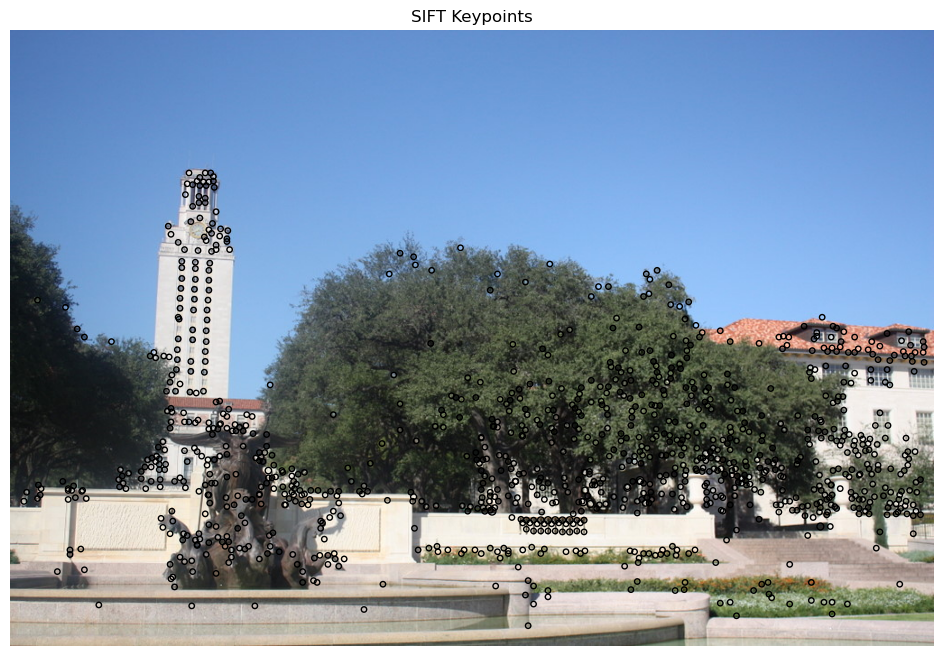

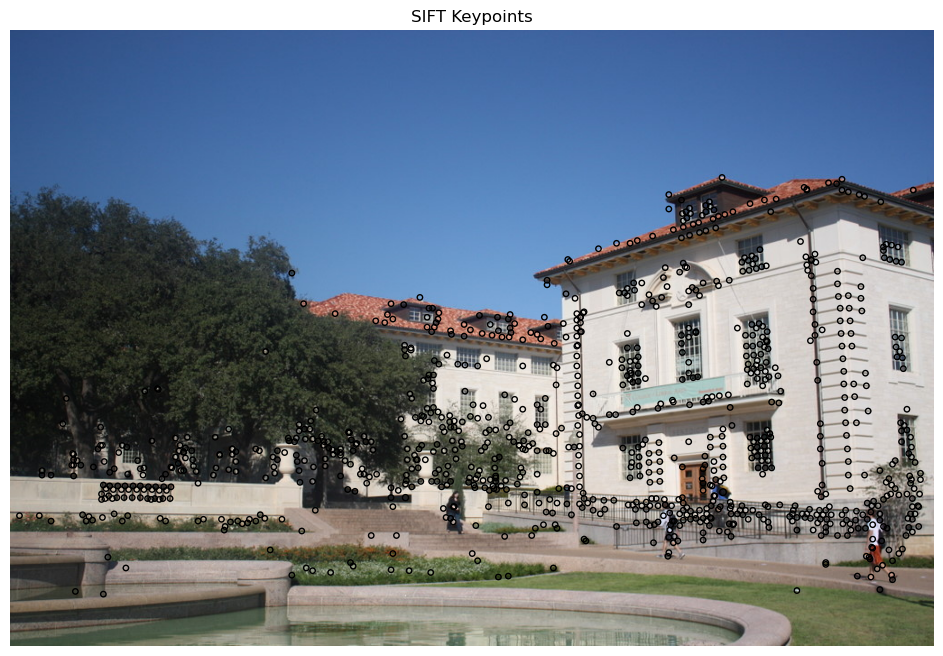

In [90]:
kp1, desc1 = detect_and_compute_sift(img1)
kp2, desc2 = detect_and_compute_sift(img2)

print(f"Image 1: {len(kp1)} keypoints")
print(f"Image 2: {len(kp2)} keypoints")

show_keypoints(img1, kp1)
show_keypoints(img2, kp2)

Found 175 matches
Ransac-  162 inliers out of 175 matches
Homography matrix:
[[ 1.32452598e+00 -7.10614976e-02 -5.83877833e+02]
 [ 1.71256790e-01  1.26209721e+00 -1.74226625e+02]
 [ 3.00557925e-04  5.64490398e-05  1.00000000e+00]]
Ransac-  162 inliers out of 175 matches
Homography matrix:
[[ 1.32452598e+00 -7.10614976e-02 -5.83877833e+02]
 [ 1.71256790e-01  1.26209721e+00 -1.74226625e+02]
 [ 3.00557925e-04  5.64490398e-05  1.00000000e+00]]


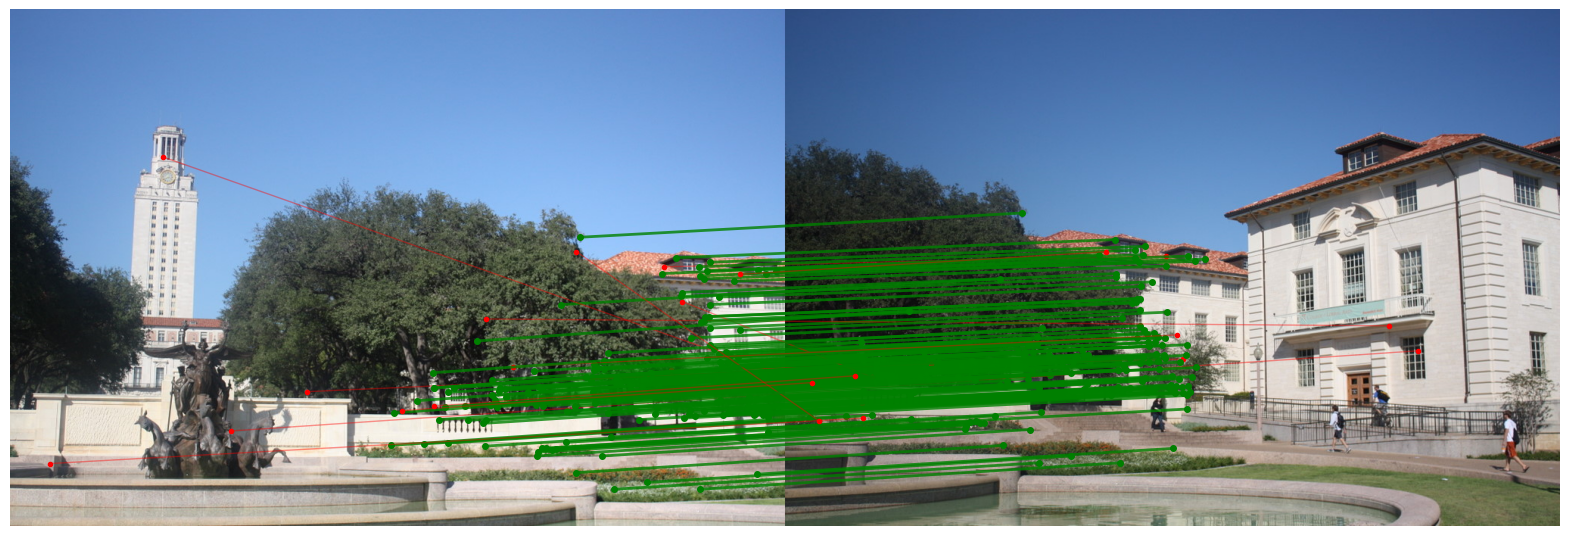

In [91]:
matches = match_descriptors(desc1, desc2)
print(f"Found {len(matches)} matches")

#ransac to find transformation matrxi
H, inliers = ransac_homography(matches, kp1, kp2)


print(f"Ransac-  {len(inliers)} inliers out of {len(matches)} matches")
print("Homography matrix:")
print(H)

show_matches(img1, img2, kp1, kp2, matches, inliers)

## Stitch Images

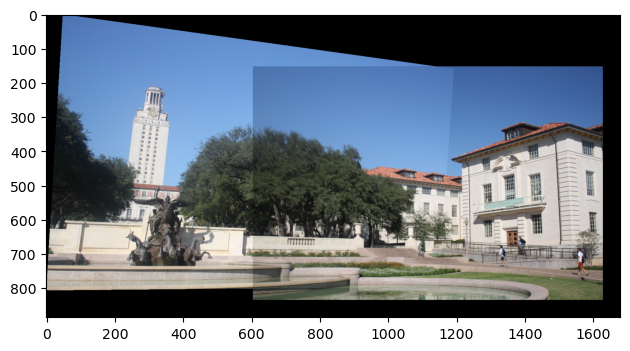

In [93]:
result, matches, inliers, keypoints = stitch_images(img1, img2)

plt.imshow(result)
plt.tight_layout()
plt.show()